# Trích chọn đặc trưng âm thanh: MFCC, Delta và Delta-Delta

**Nguồn lý thuyết:** *Spoken Language Processing*  
- Chương 6 – *Speech Signal Representations*: LPC, Cepstral Processing, Mel-Frequency Cepstrum (MFCC), PLP.
- Chương 9, Mục 9.3 – *Signal Processing—Extracting Features*: Signal Acquisition, End-Point Detection, MFCC and Its Dynamic Features, Feature Transformation.

**Dữ liệu áp dụng:** `NLinh_1.wav`

## Mục tiêu

Notebook này thực hiện theo chuỗi:

**WAV → đọc tín hiệu → chuyển mono → chuẩn hóa → quan sát waveform → MFCC → Delta → Delta-Delta → ghép vector đặc trưng → trực quan hóa → lưu đặc trưng.**

Theo tài liệu, mô-đun signal processing có nhiệm vụ giảm lượng dữ liệu, loại nhiễu và trích ra các đặc trưng nổi bật để phục vụ bước acoustic matching. MFCC là một trong những biểu diễn đặc trưng quan trọng cho speech recognition.


## 1. Kiến thức cốt lõi cần nhớ

### 1.1. Tại sao phải trích chọn đặc trưng?

Tín hiệu tiếng nói ban đầu là một chuỗi mẫu theo thời gian. Nếu đưa toàn bộ waveform trực tiếp vào các thuật toán nhận dạng, lượng dữ liệu lớn và các biến thiên của người nói, môi trường, kênh thu... gây khó khăn.

Mục tiêu của feature extraction là biến tín hiệu thành một chuỗi **vector đặc trưng có kích thước nhỏ hơn nhưng vẫn giữ thông tin âm học quan trọng**.

Dạng tổng quát:

$$
x[n] \rightarrow c_t
$$

trong đó $c_t$ là vector đặc trưng của frame thứ $t$.

Tài liệu đặt feature extraction trong module signal processing của hệ thống nhận dạng tiếng nói.


## 2. Cơ sở từ Chương 6

### 2.1. Short-time analysis

Tiếng nói thay đổi theo thời gian nên thường được phân tích trên những đoạn ngắn thay vì toàn bộ tín hiệu cùng lúc.

Một frame có thể được tạo bằng:

$$
x_t[n] = x[n+tN]w[n]
$$

trong đó:
- $x[n]$: tín hiệu tiếng nói;
- $w[n]$: cửa sổ;
- $t$: chỉ số frame;
- $N$: bước dịch giữa các frame.

Sau đó phân tích phổ bằng DFT/FFT.

### 2.2. LPC

LPC (*Linear Predictive Coding*) mô hình hóa speech bằng một bộ lọc all-pole:

$$
H(z)=\frac{G}{A(z)}
$$

với

$$
A(z)=1-\sum_{k=1}^{p}a_kz^{-k}
$$

Các hệ số LPC mô tả đặc tính của bộ lọc/vocal tract. Tài liệu mô tả LPC là một phương pháp mạnh để phân tích tiếng nói vì nhanh, đơn giản và hiệu quả.

**Vai trò trong notebook:** LPC được dùng để hiểu nền tảng của speech representation; bài thực hành chính tập trung vào MFCC vì đây là đặc trưng được Mục 9.3 sử dụng trực tiếp.


### 2.3. Cepstral processing

Speech có thể được nhìn theo mô hình source-filter:

$$
x[n]=e[n]*h[n]
$$

Trong miền cepstrum, phép tích chập trở thành phép cộng:

$$
\hat{x}[n]=\hat{e}[n]+\hat{h}[n]
$$

Nhờ đó cepstrum có thể hỗ trợ tách thông tin nguồn kích thích và bộ lọc.

Ý tưởng quan trọng cần nhớ:

**convolution trong miền thời gian → addition trong miền cepstrum.**

MFCC kế thừa ý tưởng cepstral nhưng đưa thêm thang tần số Mel để phù hợp hơn với đặc tính cảm nhận của hệ thính giác.


## 3. MFCC – đặc trưng chính

Theo Chương 6, MFCC được định nghĩa là real cepstrum của tín hiệu ngắn hạn đã được windowing và biến đổi FFT, nhưng sử dụng **thang tần số phi tuyến Mel** để xấp xỉ đặc tính của hệ thính giác.

Chuỗi xử lý:

$$
\boxed{
Speech
\rightarrow
Framing
\rightarrow
Window
\rightarrow
FFT
\rightarrow
Mel\ Filterbank
\rightarrow
Log
\rightarrow
DCT
\rightarrow
MFCC
}
$$

### Bước 1 – FFT

Từ frame $x[n]$, tính phổ:

$$
X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi nk/N}
$$

Thường quan tâm đến power spectrum:

$$
|X[k]|^2
$$

### Bước 2 – Mel filterbank

Các bộ lọc tam giác được đặt trên thang Mel. Công thức chuyển đổi thường dùng:

$$
Mel(f)=1125\ln\left(1+\frac{f}{700}\right)
$$

Điểm quan trọng: các filter không trải đều theo Hz mà trải theo Mel.

### Bước 3 – Log filter-bank energy

Với filter thứ $m$:

$$
S[m]=\ln\left(\sum_k |X[k]|^2H_m[k]\right)
$$

### Bước 4 – DCT

MFCC được tính bằng DCT của các log filter-bank energies:

$$
c[n]=\sum_{m=0}^{M-1}S[m]
\cos\left(\frac{\pi n(m+1/2)}{M}\right)
$$

Tài liệu ghi nhận trong speech recognition thường chỉ sử dụng một số lượng nhỏ cepstral coefficients; 13 hệ số đầu là một lựa chọn điển hình.


## 4. Delta và Delta-Delta – dynamic features

MFCC tĩnh mô tả đặc điểm phổ của từng frame, nhưng speech còn có **sự thay đổi theo thời gian**.

Vì vậy ta bổ sung:

- **Delta ($\Delta$)**: tốc độ thay đổi của MFCC.
- **Delta-Delta ($\Delta^2$)**: thay đổi bậc hai, phản ánh động học cao hơn.

Một dạng tính delta phổ biến:

$$
\Delta c_t =
\frac{\sum_{n=1}^{N}n(c_{t+n}-c_{t-n})}
{2\sum_{n=1}^{N}n^2}
$$

Sau đó có thể tính delta-delta bằng cách áp dụng cùng ý tưởng lên chuỗi delta:

$$
\Delta^2 c_t = \Delta(\Delta c_t)
$$

Do đó vector cuối cùng thường có dạng:

$$
\mathbf{x}_t=
[
c_t,\Delta c_t,\Delta^2c_t
]
$$

Nếu dùng 13 MFCC:

$$
13+13+13=39
$$

**Ý nghĩa:** MFCC = trạng thái phổ; Delta = xu hướng thay đổi; Delta-Delta = gia tốc của thay đổi.


## 5. Feature transformation

Sau khi có feature vector, tài liệu đề cập việc biến đổi đặc trưng để:
- giảm ảnh hưởng của noise/channel distortion/speaker variation;
- cải thiện khả năng phân tách lớp;
- giảm số chiều.

Ví dụ trong tài liệu là **PCA** khi kết hợp static MFCC với dynamic features. PCA tìm các hướng chính dựa trên eigenvectors của covariance/autocorrelation matrix và có thể loại bỏ những thành phần có eigenvalue nhỏ.

Trong notebook này, ta **không áp dụng PCA mặc định** để giữ nguyên MFCC + Delta + Delta-Delta và dễ kiểm tra ý nghĩa vật lý của từng nhóm đặc trưng.


## 6. MFCC, LPC, PLP khác nhau thế nào?

| Đặc trưng | Ý tưởng chính | Vai trò |
|---|---|---|
| LPC | Mô hình hóa speech bằng mô hình all-pole | Phân tích vocal-tract/spectral envelope |
| LPC-Cepstrum | Biến LPC thành miền cepstral | Biểu diễn nhỏ gọn hơn |
| MFCC | Mel filterbank + log + DCT | Đặc trưng phổ theo cảm nhận thính giác |
| PLP | Power spectrum có điều chỉnh theo cảm nhận + LPC/cepstrum | Biểu diễn perceptual khác MFCC |

Theo Chương 6, PLP dùng LPC nhưng thay power spectrum thông thường bằng một power spectrum có động cơ cảm nhận (*perceptually motivated*).

**Trong bài thực hành:** chọn MFCC + Delta + Delta-Delta vì đây là đúng nhóm đặc trưng được Mục 9.3.3 nhấn mạnh.


# PHẦN THỰC HÀNH TRÊN `NLinh_1.wav`

## 7. Cài đặt/import thư viện

`librosa` cung cấp các hàm xử lý speech và tính MFCC/delta; `soundfile` dùng để đọc/ghi WAV; `numpy` và `matplotlib` dùng cho tính toán và trực quan hóa.


In [15]:
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf

print("librosa:", librosa.__version__)
print("numpy:", np.__version__)


librosa: 0.11.0
numpy: 2.4.4


## 8. Đọc file WAV

File thực hành được đọc ở dạng waveform.

Nếu file stereo, ta chuyển về mono để có một chuỗi tín hiệu duy nhất:

$$
x_{mono}[n]=\\frac{x_L[n]+x_R[n]}{2}
$$

Điều này làm cho việc tính MFCC đơn giản và phù hợp với bài thực hành trích chọn đặc trưng speech.


In [16]:
AUDIO_PATH = "NLinh_1.wav"

if not os.path.exists(AUDIO_PATH):
    raise FileNotFoundError(
        f"Không tìm thấy {AUDIO_PATH}. "
        "Hãy đặt file WAV cùng thư mục với notebook."
    )

y, sr = librosa.load(AUDIO_PATH, sr=None, mono=True)

duration = len(y) / sr

print("Sampling rate:", sr, "Hz")
print("Số mẫu:", len(y))
print("Thời lượng:", round(duration, 3), "giây")
print("Min:", np.min(y))
print("Max:", np.max(y))


Sampling rate: 48000 Hz
Số mẫu: 286080
Thời lượng: 5.96 giây
Min: -0.27015686
Max: 0.32713318


### Kết quả dữ liệu của file hiện tại

File `NLinh_1.wav` có:
- Sampling rate: **48,000 Hz**
- Thời lượng: khoảng **5.96 giây**
- File gốc là stereo; khi đọc với `mono=True`, hai kênh được quy về một waveform mono.

Các giá trị cụ thể được notebook tính lại trực tiếp khi chạy.


## 9. Chuẩn hóa biên độ

Chuẩn hóa giúp biên độ tín hiệu nằm trong khoảng thuận tiện:

$$
y[n] \leftarrow \frac{y[n]}{\max |y[n]|}
$$

Đây không phải là MFCC, mà là bước chuẩn bị dữ liệu trước khi phân tích.


In [17]:
max_abs = np.max(np.abs(y))

if max_abs > 0:
    y_norm = y / max_abs
else:
    y_norm = y.copy()

print("Max |y_norm| =", np.max(np.abs(y_norm)))


Max |y_norm| = 1.0


## 10. Quan sát waveform

Waveform cho biết biên độ của speech thay đổi theo thời gian.

Điểm cần nhớ: waveform chứa rất nhiều mẫu và khó dùng trực tiếp để mô tả đầy đủ đặc tính âm học. Vì vậy ta chuyển sang biểu diễn theo frame và trích đặc trưng.


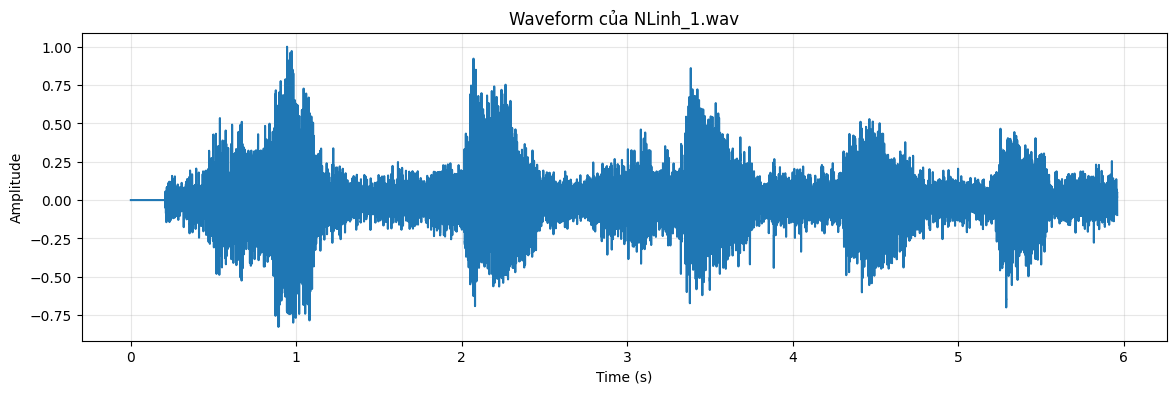

In [18]:
time = np.arange(len(y_norm)) / sr

plt.figure(figsize=(14, 4))
plt.plot(time, y_norm)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Waveform của NLinh_1.wav")
plt.grid(True, alpha=0.3)
plt.show()


## 11. Short-time framing

Ta chọn:
- `n_fft = 2048`
- `win_length = 0.025 × sr` ≈ 25 ms
- `hop_length = 0.010 × sr` ≈ 10 ms
- cửa sổ Hann.

Đây là cách biểu diễn thực hành gần với tư tưởng short-time analysis trong Chương 6: thay vì xử lý toàn bộ speech như một tín hiệu duy nhất, ta phân tích các đoạn ngắn liên tiếp.


In [19]:
n_fft = 2048
win_length = int(0.025 * sr)   # 25 ms
hop_length = int(0.010 * sr)   # 10 ms

print("n_fft:", n_fft)
print("win_length:", win_length, "samples")
print("hop_length:", hop_length, "samples")
print("win_length:", round(win_length / sr * 1000, 2), "ms")
print("hop_length:", round(hop_length / sr * 1000, 2), "ms")


n_fft: 2048
win_length: 1200 samples
hop_length: 480 samples
win_length: 25.0 ms
hop_length: 10.0 ms


## 12. Tính MFCC

Ta dùng:
- `n_mfcc = 13`: 13 hệ số MFCC;
- `n_mels = 40`: 40 bộ lọc Mel;
- `fmin = 20 Hz`;
- `fmax = sr/2`.

Kết quả có dạng:

$$
MFCC \in \mathbb{R}^{13\times T}
$$

với $T$ là số frame.


In [20]:
n_mfcc = 13
n_mels = 40
fmin = 20
fmax = sr / 2

mfcc = librosa.feature.mfcc(
    y=y_norm,
    sr=sr,
    n_mfcc=n_mfcc,
    n_fft=n_fft,
    hop_length=hop_length,
    win_length=win_length,
    window="hann",
    n_mels=n_mels,
    fmin=fmin,
    fmax=fmax
)

print("Shape MFCC:", mfcc.shape)
print("13 hệ số ×", mfcc.shape[1], "frames")


Shape MFCC: (13, 597)
13 hệ số × 597 frames


## 13. Trực quan hóa MFCC

Mỗi cột tương ứng với một frame.

- Trục ngang: thời gian.
- Trục dọc: chỉ số MFCC.
- Màu: giá trị của coefficient.

Đây là cách quan sát sự thay đổi của spectral features theo thời gian.


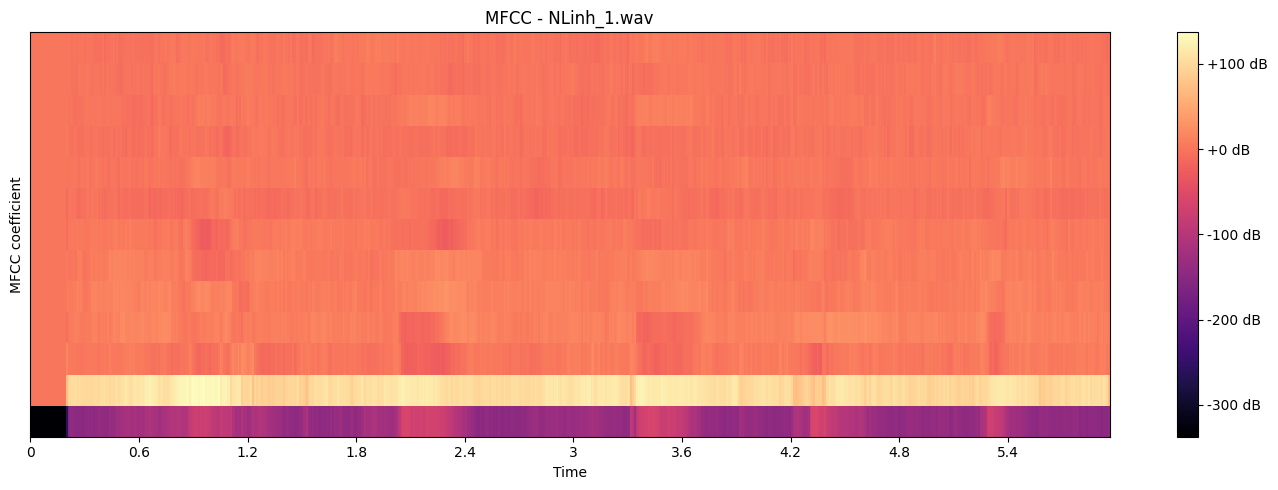

In [21]:
plt.figure(figsize=(14, 5))
img = librosa.display.specshow(
    mfcc,
    x_axis="time",
    sr=sr,
    hop_length=hop_length,
    cmap="magma"
)
plt.colorbar(img, format="%+2.0f dB")
plt.title("MFCC - NLinh_1.wav")
plt.ylabel("MFCC coefficient")
plt.tight_layout()
plt.show()


## 14. Tính Delta

Delta mô tả sự thay đổi của MFCC theo thời gian.

Ta sử dụng `width=9`, tương ứng một cửa sổ đối xứng gồm các frame lân cận khi ước lượng đạo hàm theo thời gian.

$$
\Delta c_t \approx
\frac{\sum_{n=1}^{N}n(c_{t+n}-c_{t-n})}
{2\sum_{n=1}^{N}n^2}
$$

Trong code, `librosa.feature.delta` thực hiện phép tính này trên ma trận MFCC.


In [22]:
delta = librosa.feature.delta(
    mfcc,
    width=9,
    order=1,
    mode="nearest"
)

print("Shape Delta:", delta.shape)


Shape Delta: (13, 597)


## 15. Tính Delta-Delta

Delta-Delta là đạo hàm bậc hai theo thời gian:

$$
\Delta^2 c_t = \Delta(\Delta c_t)
$$

Nó mô tả sự thay đổi của tốc độ thay đổi MFCC.


In [23]:
delta_delta = librosa.feature.delta(
    mfcc,
    width=9,
    order=2,
    mode="nearest"
)

print("Shape Delta-Delta:", delta_delta.shape)


Shape Delta-Delta: (13, 597)


## 16. So sánh ba nhóm đặc trưng

Ta có:

$$
MFCC = c_t
$$

$$
Delta = \Delta c_t
$$

$$
Delta\text{-}Delta = \Delta^2 c_t
$$

Ba nhóm này mô tả lần lượt:
1. **đặc điểm phổ hiện tại**;
2. **xu hướng thay đổi**;
3. **gia tốc của thay đổi**.


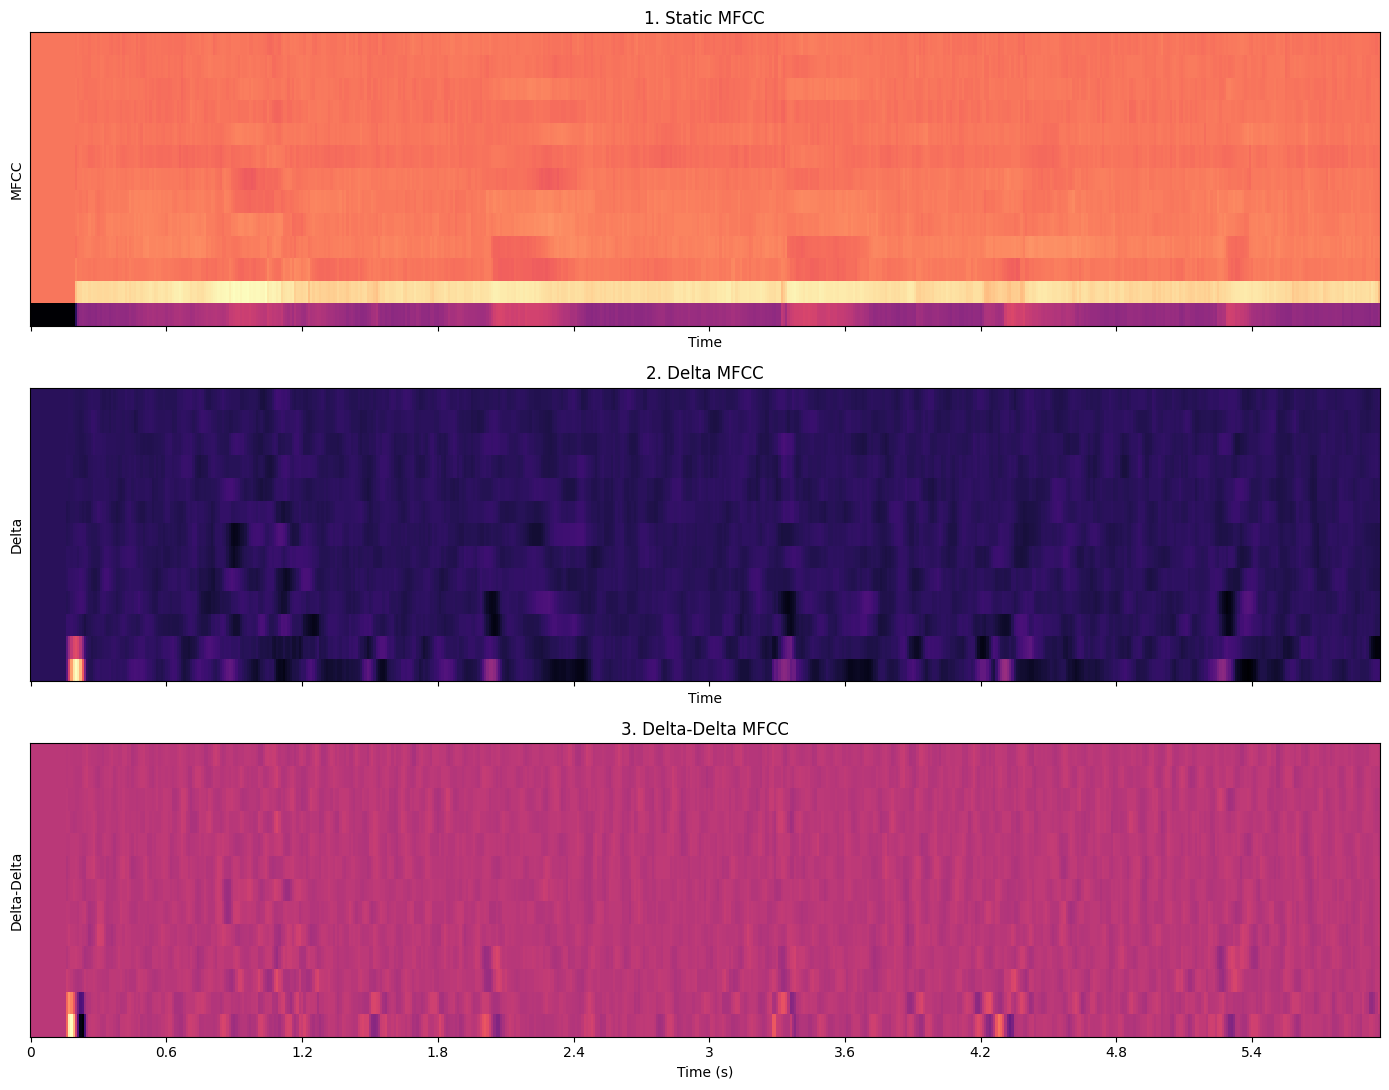

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

librosa.display.specshow(
    mfcc, x_axis="time", sr=sr, hop_length=hop_length,
    ax=axes[0], cmap="magma"
)
axes[0].set_title("1. Static MFCC")
axes[0].set_ylabel("MFCC")

librosa.display.specshow(
    delta, x_axis="time", sr=sr, hop_length=hop_length,
    ax=axes[1], cmap="magma"
)
axes[1].set_title("2. Delta MFCC")
axes[1].set_ylabel("Delta")

librosa.display.specshow(
    delta_delta, x_axis="time", sr=sr, hop_length=hop_length,
    ax=axes[2], cmap="magma"
)
axes[2].set_title("3. Delta-Delta MFCC")
axes[2].set_ylabel("Delta-Delta")
axes[2].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()


## 17. Ghép thành feature vector 39 chiều

Với 13 MFCC:

$$
13\ (static)+13\ (delta)+13\ (delta\text{-}delta)=39
$$

Ta ghép theo chiều feature:

$$
X_t =
[c_t,\Delta c_t,\Delta^2c_t]
$$

Kết quả:

$$
X \in \mathbb{R}^{39\times T}
$$

Khi dùng cho machine learning, thông thường mỗi frame sẽ là **một hàng**, nên ta chuyển thành:

$$
X_{ML}\in\mathbb{R}^{T\times39}
$$


In [25]:
features = np.vstack([
    mfcc,
    delta,
    delta_delta
])

X_ml = features.T

print("Feature matrix dạng librosa:", features.shape)
print("Feature matrix cho ML:", X_ml.shape)
print("Số chiều mỗi frame:", X_ml.shape[1])


Feature matrix dạng librosa: (39, 597)
Feature matrix cho ML: (597, 39)
Số chiều mỗi frame: 39


## 18. Kiểm tra một frame đặc trưng

Mỗi frame có 39 giá trị:

- vị trí 1–13: MFCC;
- vị trí 14–26: Delta;
- vị trí 27–39: Delta-Delta.

Điều này giúp ta kiểm tra trực tiếp vector đặc trưng mà một thuật toán ML sẽ nhận.


In [26]:
frame_index = min(10, len(X_ml) - 1)

one_frame = X_ml[frame_index]

print("Frame:", frame_index)
print("Số chiều:", len(one_frame))
print("\n13 MFCC:")
print(one_frame[:13])

print("\n13 Delta:")
print(one_frame[13:26])

print("\n13 Delta-Delta:")
print(one_frame[26:39])


Frame: 10
Số chiều: 39

13 MFCC:
[-337.5999    0.        0.        0.        0.        0.        0.
    0.        0.        0.        0.        0.        0.    ]

13 Delta:
[ 1.171285e-15 -0.000000e+00 -0.000000e+00 -0.000000e+00 -0.000000e+00
 -0.000000e+00 -0.000000e+00 -0.000000e+00 -0.000000e+00 -0.000000e+00
 -0.000000e+00 -0.000000e+00 -0.000000e+00]

13 Delta-Delta:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 19. Thống kê đặc trưng toàn đoạn

Ngoài ma trận theo frame, ta có thể tạo một vector tổng hợp bằng cách lấy mean và standard deviation theo thời gian.

$$
\mu_j=\frac{1}{T}\sum_t X_{t,j}
$$

$$
\sigma_j=
\sqrt{\frac{1}{T}\sum_t(X_{t,j}-\mu_j)^2}
$$

Khi đó mỗi file có:

$$
39+39=78
$$

đặc trưng thống kê.

**Lưu ý:** vector 78 chiều này là phần mở rộng thực hành để biến toàn bộ file thành một vector cố định; nó không phải là định nghĩa MFCC trong tài liệu.


In [27]:
feature_mean = np.mean(X_ml, axis=0)
feature_std = np.std(X_ml, axis=0)

global_feature = np.concatenate([feature_mean, feature_std])

print("Mean shape:", feature_mean.shape)
print("Std shape:", feature_std.shape)
print("Global feature shape:", global_feature.shape)


Mean shape: (39,)
Std shape: (39,)
Global feature shape: (78,)


## 20. Lưu đặc trưng

Ta lưu hai dạng:

1. `NLinh_1_mfcc_delta_features.npy`: ma trận 39 × T, giữ đầy đủ thông tin theo frame.
2. `NLinh_1_global_features.npy`: vector 78 chiều gồm mean + std.

Dạng thứ nhất phù hợp khi cần giữ thông tin động theo thời gian. Dạng thứ hai thuận tiện khi một thuật toán ML yêu cầu mỗi file là một vector cố định.


In [28]:
np.save("NLinh_1_mfcc_delta_features.npy", features)
np.save("NLinh_1_global_features.npy", global_feature)

print("Đã lưu:")
print("- NLinh_1_mfcc_delta_features.npy")
print("- NLinh_1_global_features.npy")


Đã lưu:
- NLinh_1_mfcc_delta_features.npy
- NLinh_1_global_features.npy


# 21. Kết luận

### Luồng kiến thức

$$
\boxed{
WAV
\rightarrow
Mono/Normalization
\rightarrow
Short\text{-}time\ framing
\rightarrow
FFT
\rightarrow
Mel\ Filterbank
\rightarrow
Log\ Energy
\rightarrow
DCT
\rightarrow
MFCC
\rightarrow
Delta
\rightarrow
Delta\text{-}Delta
}
$$

### Kết quả trên `NLinh_1.wav`

Notebook tạo được:

- **13 MFCC** cho mỗi frame;
- **13 Delta**;
- **13 Delta-Delta**;
- tổng cộng **39 đặc trưng/frame**;
- thêm tùy chọn **78 đặc trưng thống kê/file** bằng mean + standard deviation.

### Liên hệ với tài liệu

- **LPC:** mô hình hóa đặc tính của bộ lọc/vocal tract.
- **Cepstrum:** biến convolution thành addition và hỗ trợ source-filter separation.
- **MFCC:** cepstral representation sử dụng Mel scale, filterbank, log và DCT.
- **Delta/Delta-Delta:** bổ sung thông tin động theo thời gian.
- **Feature transformation:** có thể tiếp tục dùng PCA/LDA hoặc các phép chuẩn hóa khi xây dựng hệ thống nhận dạng.

Trong bài này, MFCC + Delta + Delta-Delta là bộ đặc trưng chính vì nó nối trực tiếp kiến thức Chương 6 với Mục 9.3.3 về **MFCC and Its Dynamic Features**.


## 22. Tài liệu tham khảo trong PDF

- Chapter 6 – *Speech Signal Representations*, đặc biệt:
  - 6.3 Linear Predictive Coding
  - 6.4 Cepstral Processing
  - 6.5.2 Mel-Frequency Cepstrum
  - 6.5.3 Perceptual Linear Prediction
- Chapter 9 – *Acoustic Modeling*, đặc biệt:
  - 9.3 Signal Processing—Extracting Features
  - 9.3.1 Signal Acquisition
  - 9.3.2 End-Point Detection
  - 9.3.3 MFCC and Its Dynamic Features
  - 9.3.4 Feature Transformation
